# Intro to TNR: Levin-Nave Tensor Renormalization Group

[TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) is a Julia package that aims to implement as many tensor network renormalization (TNR) schemes as possible. Built on top of [TensorKit.jl](https://github.com/QuantumKitHub/TensorKit.jl), it provides a symmetry-aware framework for constructing tensor network representations of partition functions and coarse graining them using methods such as TRG, HOTRG, and LoopTNR. Several models like the classical Ising, clock, and six vertex models are included, as well as the ability to construct custom (1+1)D quantum models.

In this tutorial, we provide an introduction to [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) by building the simplest TNR scheme, the Levin-Nave **Tensor Renormalization Group (TRG)**. Taking the 2D classical Ising model as an example, we implement the scheme from scratch using the [TensorKit.jl](https://github.com/QuantumKitHub/TensorKit.jl) package, and compare to the [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) interface. In going through this first example, we assume the reader is familiar with tensor networks, but no prior knowledge about TNR is required as we aim to keep this discussion as beginner-friendly as possible. That said, it is a good idea to read the original paper:

> V. Vanthilt, A. Naravane, C. Meng and A. Ueda, A practical introduction to tensor network renormalization with TNRKit.jl, SciPost Phys. Codebases 77 (2026), [doi:10.21468/SciPostPhysCodeb.77](https://scipost.org/10.21468/SciPostPhysCodeb.77).

We aim to keep this tutorial as intuitive and simple as possible by restricting to the basic functionality of [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl). A more in-depth elaboration can be found in the *Notes*, ***the subsequent tutorials???***, or in the [documentation](https://quantumkithub.github.io/TNRKit.jl/stable/).

In [2]:
using TensorKit
import MatrixAlgebraKit as MAK
import TNRKit

## Constructing the Tensor Network Representation

The partition function for the 2D classical Ising model on a square lattice is:
$$
Z = \sum_{\{\sigma = \pm 1\}} \prod_{(x, \hat{\mu})} \mathrm{e}^{\beta \sigma_x \sigma_{x+\hat{\mu}}}
$$
where $(x, \hat{\mu})$ represents a link from site $x$ to site $x + \hat{\mu}$. This model has a global $\mathbb{Z}_2$ symmetry as it remains invariant under the spin-flip transformation $\sigma_x \rightarrow -\sigma_x, \forall x$. In this construction, the spins are placed on the vertices, while the tensors $W_{\sigma_x \sigma_{x + \hat{\mu}}} = \mathrm{e}^{\beta \sigma_x \sigma_{x+\hat{\mu}}}$ live on the edges of the lattice:

***TODO: svg fig & referencing***

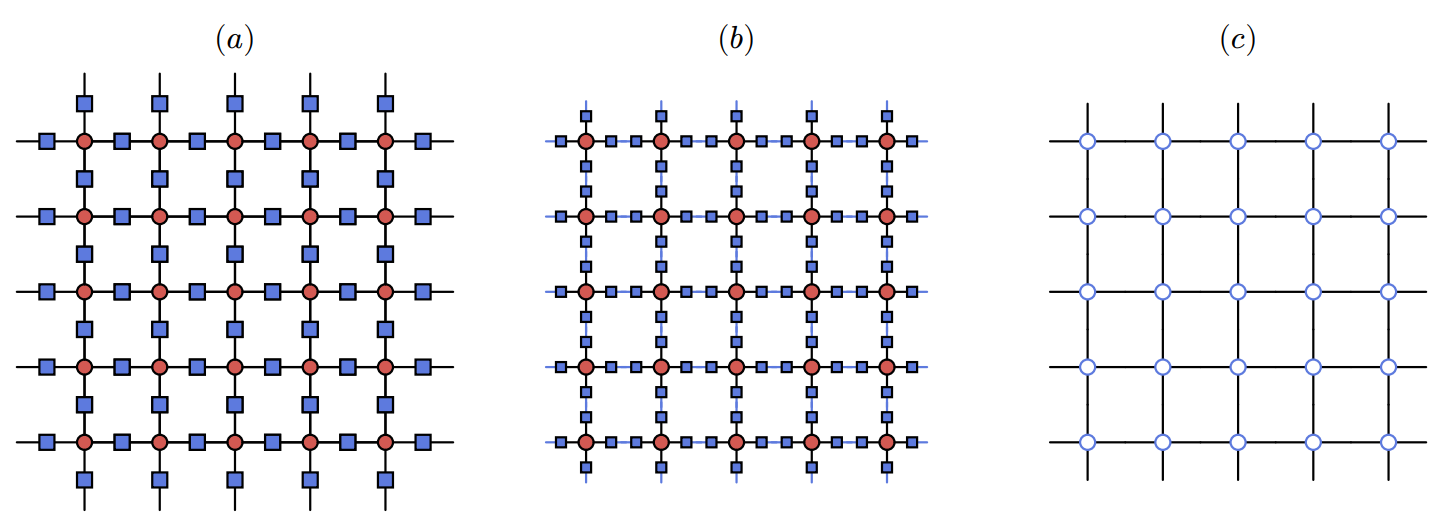

To go over to a representation with tensors living on the lattice sites, we perform a **character expansion** by factorizing the Boltzmann tensors:
$$
W_{\sigma_x \sigma_{x + \hat{\mu}}} = \mathrm{e}^{\beta \sigma_x \sigma_{x+\hat{\mu}}} = [M M^\mathrm{T}]_{\sigma_x \sigma_{x + \hat{\mu}}} \hspace{2cm} M = \begin{pmatrix} \sqrt{\cosh \beta} & \sqrt{\sinh \beta} \\ \sqrt{\cosh \beta} & -\sqrt{\sinh \beta} \end{pmatrix}
$$
where in matrix notation the first index corresponds to $\sigma = +1$ and the second index corresponds to $\sigma = -1$. By collecting the 4 neighboring tensors $M$ for each site and performing the sum over spins, the tensor $T$ situated at the vertices is obtained. Note that this tensor is the same everywhere on an infinite square lattice. The partition function can now be written as a **tensor trace**, which is the contraction of the tensor network:
$$
Z = \mathrm{tTr} \left[ \bigotimes_x T^{(x)} \right]
$$
The code to calculate this initial tensor is given in the cell below.

In [13]:
function classical_ising(β::Real)
    c = sqrt(cosh(β))
    s = sqrt(sinh(β))
    M = TensorMap(Float64[c s; c -s], ℂ^2, ℂ^2)

    δ = zeros(Float64, ℂ^2 ⊗ ℂ^2, ℂ^2 ⊗ ℂ^2)
    for i in 1:2
        δ[i, i, i, i] = 1.0
    end

    @plansor T[-1 -2; -3 -4] := δ[1 2; 3 4] * adjoint(M)[-1; 1] * adjoint(M)[-2; 2] * M[3; -3] * M[4; -4]
    return T
end

classical_ising(1.0)

2×2←2×2 TensorMap{Float64, ComplexSpace, 2, 2, Vector{Float64}}:
 codomain: (ℂ^2 ⊗ ℂ^2)
 domain: (ℂ^2 ⊗ ℂ^2)
 blocks: 
 * Trivial() => 4×4 reshape(view(::Vector{Float64}, 1:16), 4, 4) with eltype Float64:
 4.7622        3.71339e-17  -2.38499e-17   3.62686
 3.71339e-17   3.62686       3.62686      -6.10135e-18
 3.71339e-17   3.62686       3.62686      -6.10135e-18
 3.62686      -8.43155e-17  -6.10135e-18   2.7622

> Note: We employ the same convention as in [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) where legs are ordered as followed: left (l), down (d), up (u), right (r). In practice, $T$ is defined as a `TensorMap` from $\mathbb{C}_u \otimes \mathbb{C}_r \rightarrow \mathbb{C}_l \otimes \mathbb{C}_d$.

This is implemented in [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) via `classical_ising(Trivial, β)`:

In [11]:
TNRKit.classical_ising(Trivial, 1.0)

2×2←2×2 TensorMap{Float64, ComplexSpace, 2, 2, Vector{Float64}}:
 codomain: (ℂ^2 ⊗ ℂ^2)
 domain: (ℂ^2 ⊗ ℂ^2)
 blocks: 
 * Trivial() => 4×4 reshape(view(::Vector{Float64}, 1:16), 4, 4) with eltype Float64:
 4.7622   0.0      0.0      3.62686
 0.0      3.62686  3.62686  0.0
 0.0      3.62686  3.62686  0.0
 3.62686  0.0      0.0      2.7622

> Note: The Ising tensor is block-diagonal, which is the manifestation of the $\mathbb{Z}_2$ symmetry. [TensorKit.jl](https://github.com/QuantumKitHub/TensorKit.jl) facilitates the implementation of symmetric tensors, which is beneficial not only for computational efficiency but also to exclude a whole class of symmetry breaking perturbations stemming from finite-precision arithmetic. By default, [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) constructs tensors with symmetry in mind. For example, the symmetric Ising tensor can be obtained via `classical_ising(Z2Irrep, β)` or `classical_ising(β)`.

In [12]:
TNRKit.classical_ising(1.0)

2×2←2×2 TensorMap{Float64, Rep[ℤ₂], 2, 2, Vector{Float64}}:
 codomain: (Rep[ℤ₂](0 => 1, 1 => 1) ⊗ Rep[ℤ₂](0 => 1, 1 => 1))
 domain: (Rep[ℤ₂](0 => 1, 1 => 1) ⊗ Rep[ℤ₂](0 => 1, 1 => 1))
 blocks: 
 * Irrep[ℤ₂](0) => 2×2 reshape(view(::Vector{Float64}, 1:4), 2, 2) with eltype Float64:
 4.7622   3.62686
 3.62686  2.7622

 * Irrep[ℤ₂](1) => 2×2 reshape(view(::Vector{Float64}, 5:8), 2, 2) with eltype Float64:
 3.62686  3.62686
 3.62686  3.62686

## The Algorithm

***TODO: svg figs & referencing***

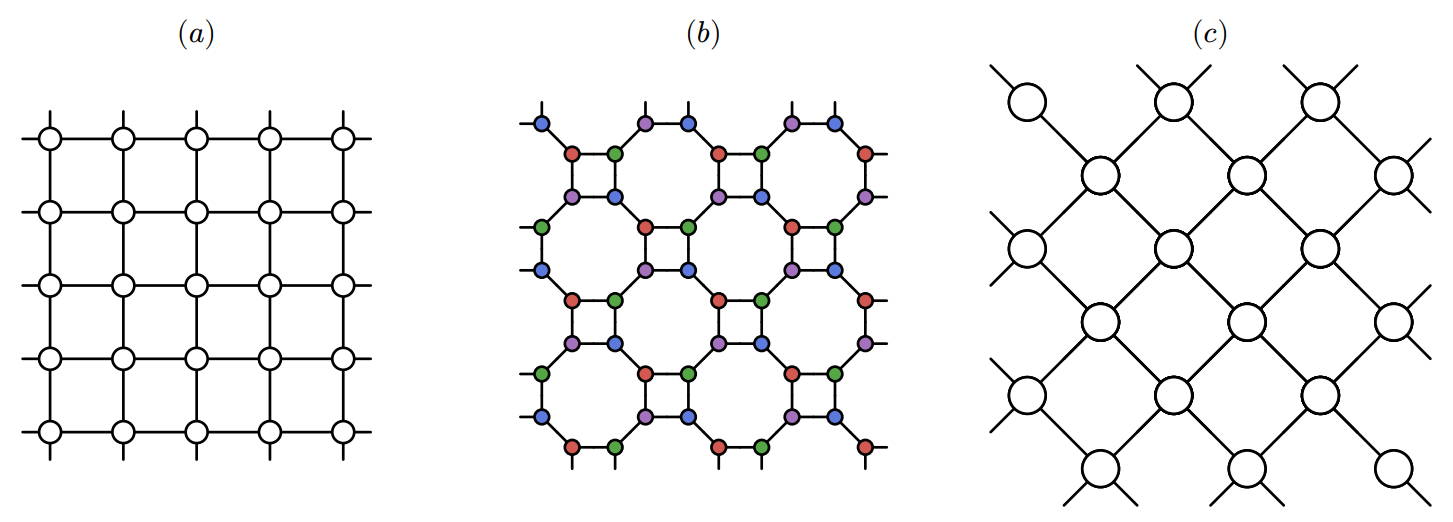

The Ising tensor $T$ - or rather, the trace thereof - represents the partition function on a $1 \times 1$ torus. In order to probe larger system sizes, this tensor has to be glued to itself both horizontally and vertically. However, for an $m \times n$ torus, we would not only have to contract $mn$ tensors, but the dimension of the resulting tensor would be $2^{2(m + n)}$ which is infeasible to implement. An obvious question is then: how do we **coarse grain** this object? How do we grow this tensor to larger lattices while discarding the irrelevant (short distance) information along the way? Levin and Nave's solution was to bring the truncated **singular value decomposition (SVD)** into the game.

The first step of TRG is to split the tensor $T$ into a pair of three-leg tensors via a SVD, where we absorb the singular values symmetrically in the isometries:
$$
T = U S V^\dagger \approx U \tilde{S} V^\dagger = (U \sqrt{\tilde{S}}) (\sqrt{\tilde{S}} V^\dagger)
$$
The two resulting tensors share a new bond, which carries the "entanglement" degrees of freedom. The singular values on this bond tell us which of these degrees of freedom matter most, and truncating to the largest $\chi$ of them is exactly the coarse graining step. Since $T$ is a four-leg tensor, legs need to be grouped together two-by-two when performing the SVD. These are either (l, d) and (u, r) or (d, r) and (l, u) depending on the position of the tensor in the lattice:

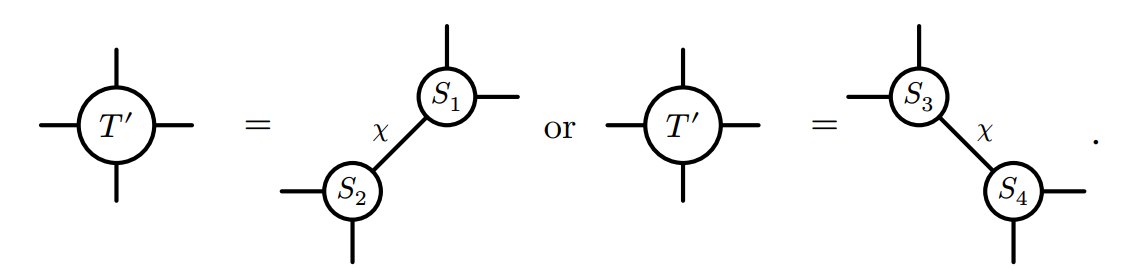

In the second step, 4 of these three-leg tensors are combined into a new coarse grained tensor $T'$. The resulting tensor network is rotated by 45 degrees and contains only half as many tensors. Therefore, after $K$ iterations, we are left with a single tensor which represents the entire lattice of size $2^{K/2} \times 2^{K/2}$.

Just as in [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl), we store the tensor in a mutable container. Note that more sophisticated TNR schemes keep track of multiple tensors.

In [14]:
mutable struct TRG
    T::AbstractTensorMap

    function TRG(T::AbstractTensorMap)
        return new(T)
    end
end

In [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl), this is provided by `TRG(T)`. The SVD and TRG step is implemented as followed:

In [16]:
function SVD12(T::AbstractTensorMap, trunc::MAK.TruncationStrategy)
    U, S, Vᴴ, _ = svd_trunc(T; trunc = trunc)
    return U * sqrt(S), sqrt(S) * Vᴴ
end


function step!(scheme::TRG, trunc::MAK.TruncationStrategy)
    A, B = SVD12(scheme.T, trunc)
    Tp = transpose(scheme.T, ((2, 4), (1, 3)))
    C, D = SVD12(Tp, trunc)
    @plansor scheme.T[-1 -2; -3 -4] := D[-2; 1 2] * B[-1; 4 1] * C[4 3; -3] * A[3 2; -4]
end

step! (generic function with 2 methods)

In practice, the tensors are normalized to prevent them growing exponentially. The default normalization factor in [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) is the norm of a $1 \times 1$ torus: $n = \mathrm{Tr} [T] = \sum_{a, b} T_{abba}$. Moreover, after $K$ iterations, the final normalized tensor $T_K / n_K$ and $1 \times 1$ norms $n_0, ..., n_K$ are all that is stored.

> Note: [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) supports other normalization methods, and these are handled through `Finalizer`s. Examples of `Finalizer`s for TRG are normalization using a $2 \times 2$ torus with `two_by_two_Finalizer`, which should be more stable, or storing only the ground state degeneracy with `GSDegeneracy_Finalizer`. Custom `Finalizer`s can also be implemented.

Our implementation of the algorithm is shown in the code cell below. The `run!` function returns an array of $1 \times 1$ norms $n_0, ..., n_K$ called `data`.

In [ ]:
function finalize!(scheme::TRG)
    n = norm(@tensor scheme.T[1 2; 2 1])
    scheme.T /= n
    return n
end


function run!(scheme::TRG, trunc::MAK.TruncationStrategy, maxiter::Int)
    data = Vector{Float64}()
    push!(data, finalize!(scheme))

    steps = 0
    while steps < maxiter
        step!(scheme, trunc)
        push!(data, finalize!(scheme))
        steps += 1
    end
    return data
end

run! (generic function with 2 methods)

In [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl), the algorithm is performed with `run!(scheme, trscheme, maxiter(n))`. Here, `trscheme` is the same as our `trunc` variable which is used in the SVD truncation, and `n` is the number of iterations. 

> Note: The more general algorithm is `run!(scheme, trscheme, criterion)` where `criterion` is of the custom `stopcrit` type which is a functor that returns `false` on the last iteration. Built-in `stopcrit`s are `maxiter(n)` which is `false` when `steps >= n`, or `convcrit(Δ, f)` which is `false` when `Δ >= f(steps, data)`. These can also be combined with the `&` operator. The `run!` function also has optional arguments such as `finalizer` to specify the `Finalizer`, whether or not to finalize the initial tensor with `finalize_beginning`, and a `verbosity` argument.

Finally, the free energy density of the system of size $N = 2^K$ can be calculated via:
$$
Z = n_0^N \mathrm{tTr}[(T_0/n_0)^{\otimes N}] = n_0^N n_1^{N/2} \mathrm{tTr}[(T_1/n_1)^{\otimes N/2}] = ...
$$
$$
\implies f = - \frac{1}{\beta} \frac{\ln Z}{N} = \sum_{k=0}^K \frac{\ln n_k}{2^k}
$$

In [25]:
function free_energy(data::Vector{Float64}, β::Real)
    lnz = sum(log(z) / 2^(i-1) for (i, z) in enumerate(data))
    return -lnz / β
end

free_energy (generic function with 1 method)

or with the [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) function `free_energy(data, β)`. Putting everything together, we can calculate the free energy density of the 2D classical Ising model in a couple of seconds:

In [30]:
T = classical_ising(TNRKit.ising_βc)
scheme = TRG(T)
data = run!(scheme, truncrank(16), 10)
free_energy(data, TNRKit.ising_βc)

-2.111058375897077484735885849799048438304724316509943981947792631976482937765773

Or, using the [TNRKit.jl](https://github.com/QuantumKitHub/TNRKit.jl) interface:

In [31]:
T = TNRKit.classical_ising(TNRKit.ising_βc)
scheme = TNRKit.TRG(T)
data = TNRKit.run!(scheme, truncrank(16), TNRKit.maxiter(10))
TNRKit.free_energy(data, TNRKit.ising_βc)

┌ Info: Starting simulation
│  TRG - Tensor Renormalization Group
│   * T: 2×2←2×2 TensorMap{Float64, Rep[ℤ₂], 2, 2, Vector{Float64}}
└ 
┌ Info: Simulation finished
│  Maximum amount of iterations reached: 10
│  Elapsed time: 0.15340774s
└  Iterations: 10


-2.111058375897075973154816061458566299089147094625914218583214792962347252268854

> Note: This is in pretty good agreement with [Onsager's exact solution](https://journals.aps.org/pr/abstract/10.1103/PhysRev.65.117).

In [27]:
TNRKit.f_onsager

-2.1096511446082075735830585472285747528076171875

## Extracting CFT Data